# Exploratory Data Analysis, STL-Decomposition and Baseline Detector Evaluation

**Master's Thesis Project:** Seasonality-Aware Drift Detection System  
**Stream A:** Data Loading, STL Decomposition, Benchmark Generation and Baseline Metrics (KS, PSI, ADWIN).

In [1]:
# Import required libraries
import sys
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.data_loader import DataLoader
from src.detector.drift_generator import DriftGenerator
from src.detector.baseline_detectors import BaselineDetectorWrapper
from src.detector.generate_benchmarks import generate_all_benchmarks
from src.detector.run_baseline_evaluation import run_all_baseline_detectors

# Styling setup
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 1. Exploratory Data Analysis (EDA)

Loaded Alibaba Trace shape: (2243, 2)


2026-10-28 13:05:08,981 | seisbench | WARNING | Check available storage and memory before downloading and general use of Iquique dataset. Dataset size: waveforms.hdf5 ~5Gb, metadata.csv ~2.6Mb
2026-10-28 13:05:09,007 | seisbench | WARNING | Output component order not specified, defaulting to 'ZNE'.


Loaded UCI Electricity shape: (35065, 2)
Loaded TCPD JFK Airline Passengers shape: (468, 2)
Ground Truth Change Points: [296]
Loaded SeisBench Iquique trace #8515. Focus: P-wave. Ground-truth CP index: 2000
Loaded SeisBench Iquique shape: (4551, 2)
Seismic Ground Truth Change Point Index: [2000]


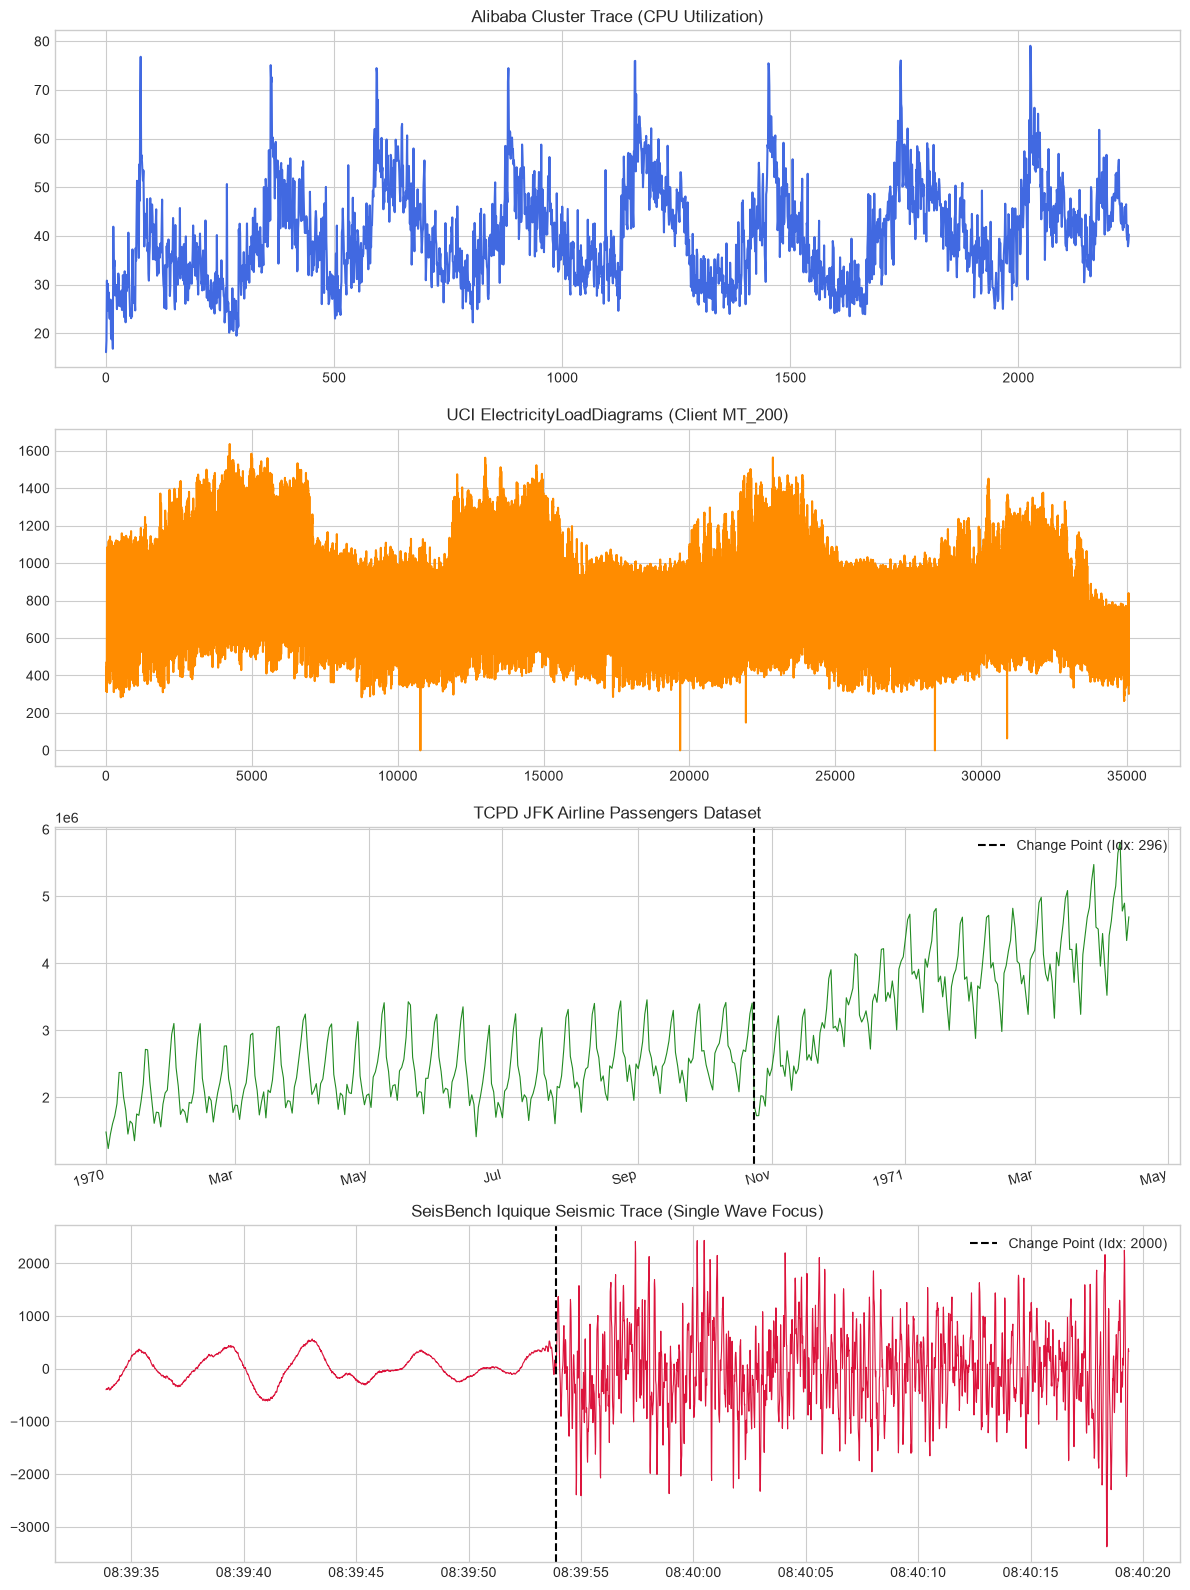

In [2]:
# Initialize data loader
loader = DataLoader(data_dir="../data")

# 1. Load Alibaba Cluster Trace (Infrastructure Domain)
try:
    alibaba_df = loader.load_alibaba_standard_trace(metric="cpu_util_percent")
    print(f"Loaded Alibaba Trace shape: {alibaba_df.shape}")
except Exception as e:
    print(f"Alibaba file note: {e}")
    alibaba_df = None

# 2. Load UCI Electricity (Energy Domain)
try:
    uci_df = loader.load_uci_electricity(client_id="MT_200", resample_freq="1h")
    print(f"Loaded UCI Electricity shape: {uci_df.shape}")
except Exception as e:
    print(f"UCI Electricity file note: {e}")
    uci_df = None

# 3. Load TCPD JFK Airline Passengers Dataset
try:
    # Adjust method name or arguments if your DataLoader uses a specific signature for TCPD
    tcpd_df, ground_truth_cps = loader.load_tcpd_annotated_series("jfk_passengers", annotator_key="10") 
    print(f"Loaded TCPD JFK Airline Passengers shape: {tcpd_df.shape}")
    print(f"Ground Truth Change Points: {ground_truth_cps}")
except Exception as e:
    print(f"TCPD JFK Airline Passengers file note: {e}")
    tcpd_df = None

# 4. Load SeisBench Iquique Dataset (Seismic Domain)
try:
    seismic_df, seismic_gt_cps = loader.load_seismic_dataset(seed=42)
    print(f"Loaded SeisBench Iquique shape: {seismic_df.shape}")
    print(f"Seismic Ground Truth Change Point Index: {seismic_gt_cps}")
except Exception as e:
    print(f"SeisBench Iquique file note: {e}")
    seismic_df = None
    seismic_gt_cps = []

# Plot raw signals side-by-side
fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=False)

if alibaba_df is not None:
    axes[0].plot(alibaba_df["value"], color="royalblue")
    axes[0].set_title("Alibaba Cluster Trace (CPU Utilization)")
else:
    axes[0].text(0.5, 0.5, "Alibaba data not found in data/raw/", ha="center")

if uci_df is not None:
    axes[1].plot(uci_df["value"], color="darkorange")
    axes[1].set_title("UCI ElectricityLoadDiagrams (Client MT_200)")
else:
    axes[1].text(0.5, 0.5, "UCI Electricity data not found in data/raw/", ha="center")

if tcpd_df is not None:
    # Use standard plotting or specific column if multi-column
    axes[2].plot(tcpd_df["timestamp"], tcpd_df["value"], color="forestgreen", linewidth=0.8)

    # Highlight the single ground-truth change point if within bounds
    for cp_idx in ground_truth_cps:
        if cp_idx < len(tcpd_df):
            cp_time = tcpd_df.loc[cp_idx, "timestamp"]
            axes[2].axvline(cp_time, color="black", linestyle="--", label=f"Change Point (Idx: {cp_idx})")

    axes[2].set_title("TCPD JFK Airline Passengers Dataset")
    axes[2].legend(loc="upper right")

    # --- Fix crowded timestamp axis ---
    # Automatically format major ticks to prevent overlapping dates/times
    axes[2].xaxis.set_major_locator(mdates.AutoDateLocator())
    axes[2].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[2].xaxis.get_major_locator()))
    
    # Optional: Rotate tick labels slightly if they still overlap
    plt.setp(axes[2].xaxis.get_majorticklabels(), rotation=15, ha="right")
else:
    axes[2].text(0.5, 0.5, "TCPD JFK Airline Passengers data not found in data/raw/", ha="center", va="center")

if seismic_df is not None:
    axes[3].plot(seismic_df["timestamp"], seismic_df["value"], color="crimson", linewidth=0.8)
    # Highlight the single ground-truth change point if within bounds
    for cp_idx in seismic_gt_cps:
        if cp_idx < len(seismic_df):
            cp_time = seismic_df.loc[cp_idx, "timestamp"]
            axes[3].axvline(cp_time, color="black", linestyle="--", label=f"Change Point (Idx: {cp_idx})")
    axes[3].set_title("SeisBench Iquique Seismic Trace (Single Wave Focus)")
    axes[3].legend(loc="upper right")
else:
    axes[3].text(0.5, 0.5, "SeisBench Iquique data could not be loaded", ha="center", va="center")

plt.tight_layout()
plt.show()

In [3]:
uci_df.head(3)

,timestamp,value
0,2011-01-01 00:00:00,415.932452
1,2011-01-01 01:00:00,368.942731
2,2011-01-01 02:00:00,349.394273


In [4]:
alibaba_df.head(3)

,timestamp,value
0,2018-01-01 00:00:00,16.126977
1,2018-01-01 00:05:00,18.466110
2,2018-01-01 00:10:00,30.822524


In [5]:
tcpd_df.head(3)

,timestamp,value
0,1977-01,1487588
1,1977-02,1237719
2,1977-03,1450395


In [6]:
seismic_df.head(3)

,timestamp,value
0,2014-04-08 08:39:33.869997+00:00,-397.223417
1,2014-04-08 08:39:33.879997+00:00,-388.223417
2,2014-04-08 08:39:33.889997+00:00,-379.223417


## 2. STL-Decomposition and Baseline Detector Evaluation (FOR 1 DATASET, for demo)

### 2.1 STL-Decomposition & Residual Extraction

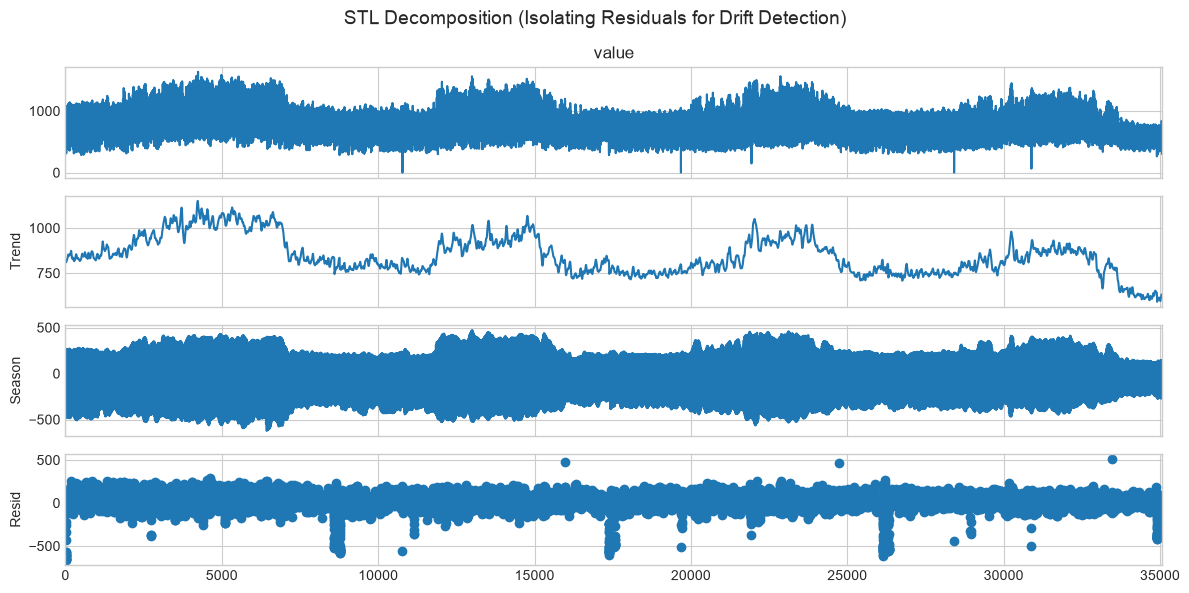

In [7]:
# Select active dataset for decomposition experiment (e.g., UCI Electricity)
active_df = uci_df
period = 24

stl = STL(active_df["value"], period=period, robust=True)
stl_result = stl.fit()

# Plot decomposition
fig = stl_result.plot()
plt.suptitle("STL Decomposition (Isolating Residuals for Drift Detection)", fontsize=14)
plt.tight_layout()
plt.show()

### 2.2 Benchmark Generation (Level 1 & 2)

In [8]:
# Initialize Drift Generator using our active target series
generator = DriftGenerator(active_df, seasonality_period=period)

# Level 1: Generate clean series (no drift) for False Alarm Rate (FAR) measurement
level1_clean_df = generator.generate_level1_baseline()

# Level 2: Inject controlled abrupt drift (Magnitude = 2.0 * sigma)
change_idx = len(active_df) // 2
level2_drift_df, metadata = generator.inject_level2_drift(
    drift_type="abrupt", 
    change_point_idx=change_idx, 
    magnitude_sigma=2.0
)

print("Level 2 Injection Metadata:", metadata)

Level 2 Injection Metadata: {'drift_type': 'abrupt', 'change_point_idx': 17532, 'change_point_timestamp': Timestamp('2012-12-31 12:00:00'), 'magnitude_sigma': 2.0, 'absolute_delta': 107.45209470654902}


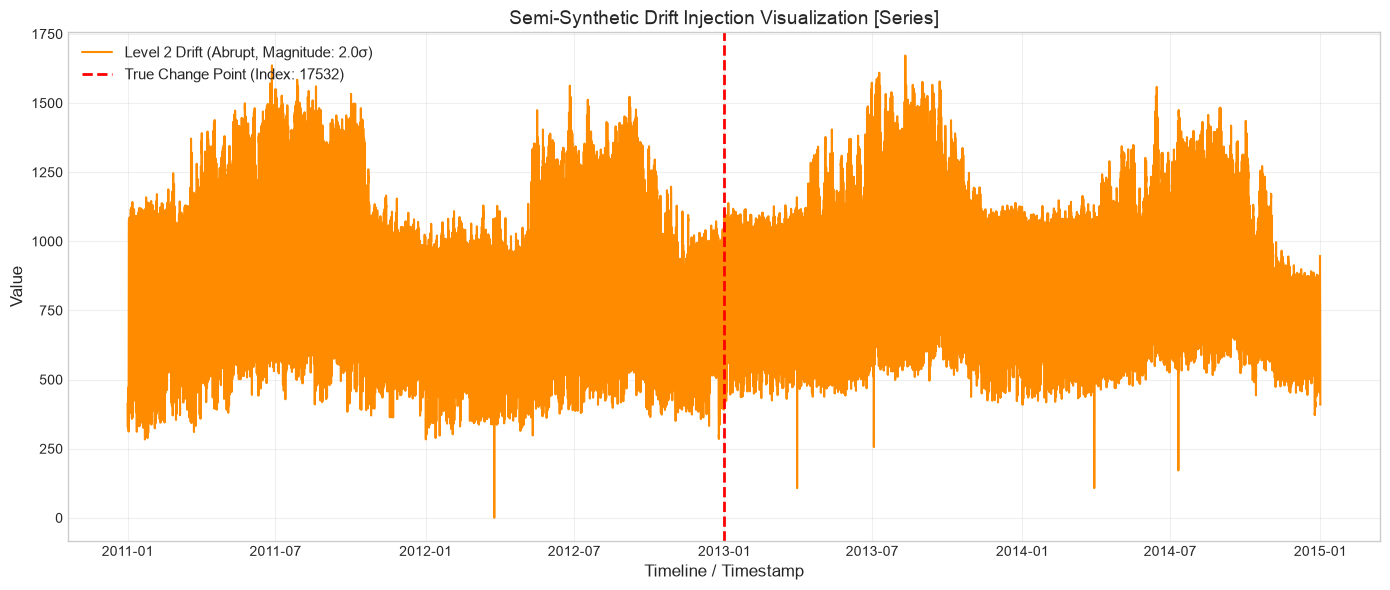

In [9]:
# Plot the drift-injected time series level2_drift_df
plt.figure(figsize=(14, 6))

# 1. Plot the drift-injected time series
plt.plot(
    level2_drift_df["timestamp"] if "timestamp" in level2_drift_df.columns else level2_drift_df.index,
    level2_drift_df["value"],
    color="darkorange",
    linewidth=1.5,
    label=f"Level 2 Drift ({metadata['drift_type'].capitalize()}, Magnitude: {metadata['magnitude_sigma']}σ)"
)

# 2. Mark the true change point
change_idx = metadata["change_point_idx"]
change_x = level2_drift_df.loc[change_idx, "timestamp"] if "timestamp" in level2_drift_df.columns else change_idx

plt.axvline(
    x=change_x, 
    color="red", 
    linestyle="--", 
    linewidth=2, 
    label=f"True Change Point (Index: {change_idx})"
)

# 3. Chart formatting
plt.title(f"Semi-Synthetic Drift Injection Visualization [{metadata['dataset_name'] if 'dataset_name' in metadata else 'Series'}]", fontsize=14)
plt.xlabel("Timeline / Timestamp", fontsize=12)
plt.ylabel("Value", fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 Baseline Detector Evaluation (Raw Data)

In [10]:
# Initialize baseline detector wrapper
detector = BaselineDetectorWrapper(method="ks", window_size=100, threshold=0.01)

# 1. Evaluate False Alarm Rate (Level 1)
clean_alerts = detector.run(level1_clean_df)
far_score = (len(clean_alerts) / len(level1_clean_df)) * 1000
print(f"--- Level 1 Evaluation ---")
print(f"False Alarm Rate (FAR) on Clean Series: {far_score:.2f} alarms per 1,000 points\n")

# 2. Evaluate Detection Performance (Level 2)
drift_alerts = detector.run(level2_drift_df)
print(f"--- Level 2 Evaluation ---")
print(f"Flagged Alerts: {drift_alerts}")

if drift_alerts:
    first_alert = drift_alerts[0]["index"]
    delay = first_alert - change_idx
    print(f"True Change Point: {change_idx} | Detected At: {first_alert} | Delay: {delay} steps")
else:
    print("No drift detected by baseline KS-test.")

--- Level 1 Evaluation ---
False Alarm Rate (FAR) on Clean Series: 1.34 alarms per 1,000 points

--- Level 2 Evaluation ---
Flagged Alerts: [{'index': 200, 'timestamp': Timestamp('2011-01-09 08:00:00'), 'method': 'ks'}, {'index': 300, 'timestamp': Timestamp('2011-01-13 12:00:00'), 'method': 'ks'}, {'index': 1000, 'timestamp': Timestamp('2011-02-11 16:00:00'), 'method': 'ks'}, {'index': 1400, 'timestamp': Timestamp('2011-02-28 08:00:00'), 'method': 'ks'}, {'index': 1475, 'timestamp': Timestamp('2011-03-03 11:00:00'), 'method': 'ks'}, {'index': 1500, 'timestamp': Timestamp('2011-03-04 12:00:00'), 'method': 'ks'}, {'index': 1525, 'timestamp': Timestamp('2011-03-05 13:00:00'), 'method': 'ks'}, {'index': 1900, 'timestamp': Timestamp('2011-03-21 04:00:00'), 'method': 'ks'}, {'index': 1925, 'timestamp': Timestamp('2011-03-22 05:00:00'), 'method': 'ks'}, {'index': 2025, 'timestamp': Timestamp('2011-03-26 09:00:00'), 'method': 'ks'}, {'index': 2225, 'timestamp': Timestamp('2011-04-03 17:00:00')

## 3. Full Benchmark Generation

In [11]:
generate_all_benchmarks(data_dir="../data")

=== Starting 3-Level Benchmark Generation ===

[Levels 1 & 2] Processing dataset: 'alibaba_cluster_trace'...
  [Level 1] Saved drift-free series -> level1_clean_alibaba_cluster_trace.csv
  [Level 2] Saved abrupt drift (0.5σ) -> level2_alibaba_cluster_trace_abrupt_mag0.5sig.csv
  [Level 2] Saved abrupt drift (1.0σ) -> level2_alibaba_cluster_trace_abrupt_mag1.0sig.csv
  [Level 2] Saved abrupt drift (2.0σ) -> level2_alibaba_cluster_trace_abrupt_mag2.0sig.csv
  [Level 2] Saved abrupt drift (3.0σ) -> level2_alibaba_cluster_trace_abrupt_mag3.0sig.csv
  [Level 2] Saved gradual drift (0.5σ) -> level2_alibaba_cluster_trace_gradual_mag0.5sig.csv
  [Level 2] Saved gradual drift (1.0σ) -> level2_alibaba_cluster_trace_gradual_mag1.0sig.csv
  [Level 2] Saved gradual drift (2.0σ) -> level2_alibaba_cluster_trace_gradual_mag2.0sig.csv
  [Level 2] Saved gradual drift (3.0σ) -> level2_alibaba_cluster_trace_gradual_mag3.0sig.csv
  [Level 2] Saved seasonal_amplitude drift (0.5σ) -> level2_alibaba_cluster_t

2026-10-28 13:05:22,162 | seisbench | WARNING | Check available storage and memory before downloading and general use of Iquique dataset. Dataset size: waveforms.hdf5 ~5Gb, metadata.csv ~2.6Mb
2026-10-28 13:05:22,189 | seisbench | WARNING | Output component order not specified, defaulting to 'ZNE'.


  [Level 2] Saved gradual drift (3.0σ) -> level2_uci_electricity_MT200_gradual_mag3.0sig.csv
  [Level 2] Saved seasonal_amplitude drift (0.5σ) -> level2_uci_electricity_MT200_seasonal_amplitude_mag0.5sig.csv
  [Level 2] Saved seasonal_amplitude drift (1.0σ) -> level2_uci_electricity_MT200_seasonal_amplitude_mag1.0sig.csv
  [Level 2] Saved seasonal_amplitude drift (2.0σ) -> level2_uci_electricity_MT200_seasonal_amplitude_mag2.0sig.csv
  [Level 2] Saved seasonal_amplitude drift (3.0σ) -> level2_uci_electricity_MT200_seasonal_amplitude_mag3.0sig.csv

[Level 1 Only] Processing clean baseline for: 'tcpd_jfk_passengers'...
  [Level 1] Saved clean baseline -> level1_clean_tcpd_jfk_passengers.csv

[Level 1 Only] Processing clean baseline for: 'seismic_iquique_trace'...
Loaded SeisBench Iquique trace #8515. Focus: P-wave. Ground-truth CP index: 2000


2026-10-28 13:05:22,534 | seisbench | WARNING | Check available storage and memory before downloading and general use of Iquique dataset. Dataset size: waveforms.hdf5 ~5Gb, metadata.csv ~2.6Mb
2026-10-28 13:05:22,561 | seisbench | WARNING | Output component order not specified, defaulting to 'ZNE'.


  [Level 1] Saved clean baseline -> level1_clean_seismic_iquique_trace.csv

[Level 3] Processing TCPD Real-World Annotated Datasets...
  -> Level 3 saved [TCPD jfk_passengers] with 1 ground-truth change points.

[Level 3] Processing SeisBench Iquique Benchmark...
Loaded SeisBench Iquique trace #8515. Focus: P-wave. Ground-truth CP index: 2000
  -> Saved [Seismic Iquique] benchmark with change point index: [2000]

3-Level Benchmark Generation Complete! Manifest saved to: ../data/processed/benchmark_manifest.json


## 4. Baseline Detector Evaluation

In [12]:
evaluation_df = run_all_baseline_detectors(data_dir="../data")

=== Starting Baseline Detector Evaluation (3-Level Benchmark) ===
[Level 1 FAR] ks on alibaba_cluster_trace: 24.07 alarms/1000 pts
[Level 1 FAR] psi on alibaba_cluster_trace: 36.11 alarms/1000 pts
[Level 1 FAR] wasserstein on alibaba_cluster_trace: 34.77 alarms/1000 pts
[Level 1 FAR] adwin on alibaba_cluster_trace: 5.80 alarms/1000 pts
[Level 1 FAR] page_hinkley on alibaba_cluster_trace: 12.48 alarms/1000 pts
[Level 1 FAR] kswin on alibaba_cluster_trace: 8.92 alarms/1000 pts
[Level 1 FAR] ks on uci_electricity_MT200: 0.91 alarms/1000 pts
[Level 1 FAR] psi on uci_electricity_MT200: 32.40 alarms/1000 pts
[Level 1 FAR] wasserstein on uci_electricity_MT200: 39.78 alarms/1000 pts
[Level 1 FAR] adwin on uci_electricity_MT200: 0.23 alarms/1000 pts
[Level 1 FAR] page_hinkley on uci_electricity_MT200: 33.31 alarms/1000 pts
[Level 1 FAR] kswin on uci_electricity_MT200: 1.63 alarms/1000 pts
[Level 1 FAR] ks on tcpd_jfk_passengers: 0.00 alarms/1000 pts
[Level 1 FAR] psi on tcpd_jfk_passengers: 17.

In [13]:
if not evaluation_df.empty:
    # Filter and display Level 1 FAR summary
    print("--- Level 1 False Alarm Rate Summary ---")
    display(evaluation_df[evaluation_df["level"] == 1][["dataset", "method", "false_alarms", "far_per_1000"]])
    
    # Filter and display Level 2 Detection Delay summary preview
    print("\n--- Level 2 Detection Delay Summary (Preview) ---")
    display(evaluation_df[evaluation_df["level"] == 2][["dataset", "drift_type", "magnitude", "method", "detection_delay", "precision", "recall", "f1_score"]].head(10))

    # Filter and display Level 3 Detection Delay summary preview
    print("\n--- Level 3 Detection Delay Summary (Preview) ---")
    display(evaluation_df[evaluation_df["level"] == 3][["dataset", "method", "detection_delay", "precision", "recall", "f1_score"]].head(10))
else:
    print("No evaluation results available yet. Ensure benchmarks are generated.")

--- Level 1 False Alarm Rate Summary ---


,dataset,method,false_alarms,far_per_1000
0,alibaba_cluster_trace,ks,54.0,24.07
1,alibaba_cluster_trace,psi,81.0,36.11
2,alibaba_cluster_trace,wasserstein,78.0,34.77
3,alibaba_cluster_trace,adwin,13.0,5.80
4,alibaba_cluster_trace,page_hinkley,28.0,12.48
5,alibaba_cluster_trace,kswin,20.0,8.92
78,uci_electricity_MT200,ks,32.0,0.91
79,uci_electricity_MT200,psi,1136.0,32.40
80,uci_electricity_MT200,wasserstein,1395.0,39.78
81,uci_electricity_MT200,adwin,8.0,0.23



--- Level 2 Detection Delay Summary (Preview) ---


,dataset,drift_type,magnitude,method,detection_delay,precision,recall,f1_score
6,alibaba_cluster_trace,abrupt,0.5,ks,4.0,0.05,1.0,0.09
7,alibaba_cluster_trace,abrupt,0.5,psi,4.0,0.03,1.0,0.05
8,alibaba_cluster_trace,abrupt,0.5,wasserstein,4.0,0.03,1.0,0.06
9,alibaba_cluster_trace,abrupt,0.5,adwin,222.0,0.00,0.0,0.00
10,alibaba_cluster_trace,abrupt,0.5,page_hinkley,37.0,0.06,1.0,0.11
11,alibaba_cluster_trace,abrupt,0.5,kswin,27.0,0.09,1.0,0.17
12,alibaba_cluster_trace,abrupt,1.0,ks,4.0,0.05,1.0,0.09
13,alibaba_cluster_trace,abrupt,1.0,psi,4.0,0.03,1.0,0.05
14,alibaba_cluster_trace,abrupt,1.0,wasserstein,4.0,0.03,1.0,0.06
15,alibaba_cluster_trace,abrupt,1.0,adwin,222.0,0.00,0.0,0.00



--- Level 3 Detection Delay Summary (Preview) ---


,dataset,method,detection_delay,precision,recall,f1_score
168,tcpd_jfk_passengers,ks,4.0,0.12,1.0,0.22
169,tcpd_jfk_passengers,psi,4.0,0.09,1.0,0.17
170,tcpd_jfk_passengers,wasserstein,4.0,0.09,1.0,0.17
171,tcpd_jfk_passengers,adwin,NaN,0.00,0.0,0.00
172,tcpd_jfk_passengers,page_hinkley,3.0,0.07,1.0,0.12
173,tcpd_jfk_passengers,kswin,NaN,0.00,0.0,0.00
174,seismic_iquique_random,ks,0.0,0.01,1.0,0.02
175,seismic_iquique_random,psi,0.0,0.01,1.0,0.01
176,seismic_iquique_random,wasserstein,0.0,0.01,1.0,0.01
177,seismic_iquique_random,adwin,15.0,0.02,1.0,0.04
